## Catalogues
This notebook looks at the table **planed CMIP6 EURO-CORDEX EUR-12**
and compares it with the **catalogue about the available data at the Jülich server**

In [121]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [122]:
import intake
import pandas as pd
import os

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from tools_catalogue_merge import *

In [123]:
# create directory for plots
os.makedirs("plots", exist_ok=True)
plot_dir = "plots"
os.makedirs(plot_dir, exist_ok=True)

## Open files

In [124]:
# URL to the CMIP6 downscaling plans CSV file (Jesus Table)
# also have a look here:
# https://wcrp-cordex.github.io/simulation-status/CORDEX_CMIP6_status.html#EUR-12

url = "https://raw.githubusercontent.com/WCRP-CORDEX/simulation-status/main/CMIP6_downscaling_plans.csv"
df = pd.read_csv(url)
df.head()
#
df.columns

Index(['domain_id', 'institution_id', 'contact', 'source_id',
       'driving_source_id', 'driving_variant_label', 'driving_experiment_id',
       'status', 'estimated_completion_date', 'comments'],
      dtype='str')

### Select what I need from planed simulations e.g. EUR-12

In [101]:
# ------------------------------------------------------------------
# Domsi selection for EUR-12 domain
# ------------------------------------------------------------------
df_eur12=df[df['domain_id']=='EUR-12']
# ------------------------------------------------------------------
# There are some rows containing EURO-CORDEX as institution_id, 
# we don not need
# ------------------------------------------------------------------
df_eur12=df_eur12[df_eur12['institution_id']!='EURO-CORDEX']
df_eur12.head()
# ------------------------------------------------------------------
# select colums of interest
# ------------------------------------------------------------------
df_eur12_small = df_eur12[['institution_id', 'source_id', 'driving_source_id', 'driving_variant_label', 'driving_experiment_id','comments']]
# ------------------------------------------------------------------
# we only want historical and ssps:
# ------------------------------------------------------------------
df_eur12_small=df_eur12_small[df_eur12_small['driving_source_id']!='ERA5']
df_eur12_small.to_csv("df_eur12_small.csv", index=False)
df_eur12_small.head()

,institution_id,source_id,driving_source_id,driving_variant_label,driving_experiment_id,comments
336,AUTH,WRF451Q,MPI-ESM1-2-HR,r1i1p1f1,historical,#EURbalanced #ManySSP #CORDEX-CORE
337,AUTH,WRF451Q,MPI-ESM1-2-HR,r1i1p1f1,ssp126,#EURbalanced #ManySSP
338,BCCR-UCAN,WRF451Q,NorESM2-MM,r1i1p1f1,historical,#EURbalanced #CORDEX-CORE
339,BCCR-UCAN,WRF451Q,NorESM2-MM,r1i1p1f1,ssp126,#EURbalanced
340,BCCR-UCAN,WRF451Q,NorESM2-MM,r1i1p1f1,ssp370,#EURbalanced #CORDEX-CORE


### Available in Jülich

In [102]:
cat = intake.open_esm_datastore("https://raw.githubusercontent.com/euro-cordex/jsc-cordex-catalog/refs/heads/main/CORDEX-CMIP6-JSC.json")
#cat#.keys()

### Available, but wrong format

### Comparison of what is planned and what is available in the catalog in Jülich

In [106]:
# This is the comparison of what is planned and what is available in the catalog
#
# ------------------------------------------------------------------
# CSV containing planned downscaling
# ------------------------------------------------------------------

df = pd.read_csv("df_eur12_small.csv")

# ------------------------------------------------------------------
# Intake-ESM Catalog with available simulations in Jülich
# ------------------------------------------------------------------

cat = intake.open_esm_datastore("https://raw.githubusercontent.com/euro-cordex/jsc-cordex-catalog/refs/heads/main/CORDEX-CMIP6-JSC.json")
cdf = cat.df

# ------------------------------------------------------------------
# Columns that together describe a model chain
# ------------------------------------------------------------------

match_cols = [
    "institution_id",
    "source_id",
    "driving_source_id",
    "driving_variant_label",
    "driving_experiment_id",
]

# ------------------------------------------------------------------
# Required variables
# ------------------------------------------------------------------

required_vars = {"tas", "pr"}
#required_vars = {"tas", "pr", "tasmin", "tasmax"}

#-------------------------------------------------------------------
# combine
#-------------------------------------------------------------------

df_com = create_combined_matrix(df,cdf,match_cols,required_vars)

# ------------------------------------------------------------------
# Save
# ------------------------------------------------------------------

df_com.to_csv(
    "CMIP6_downscaling_plans_checked.csv",
    index=False
)

# Create plots

# Test reading esgf search results

# Open esgf search

https://metagrid-ceda.east.esgf.io/search
22 Okt 2026

In [118]:
import json

with open("search.geojson", "r") as search_file:
    search_data = search_file.read()

search_df = pd.json_normalize(
    json.loads(search_data)["features"],
    sep="."
)

id_parts = search_df["id"].str.split(".", expand=True)
base_id_columns = [
    "project",
    "activity_id",
    "domain_id",
    "institution_id",
    "driving_source_id",
    "driving_experiment_id",
    "driving_variant_label",
    "source_id",
    "version_realization",
    "frequency",
    "variable_id",
    "data_version",
]
id_parts.columns = [
    base_id_columns[index] if index < len(base_id_columns) else f"id_part_{index + 1}"
    for index in range(id_parts.shape[1])
]

search_df_split = pd.concat([search_df[["id"]], id_parts], axis=1)
search_df_split.to_csv("search_df_split_id.csv", index=False)
#search_df_split



# Combine CMIP6 down scaling plans checked at Jülich with available simulations in esgf

In [125]:

#-----------------------------------------------------
# Load CMIP6 downscaling plans check availability at Jülich
#-----------------------------------------------------

df = pd.read_csv("CMIP6_downscaling_plans_checked.csv")
#-----------------------------------------------------
# Load ESGF search results for daily data
#-----------------------------------------------------
 
search_df_split = pd.read_csv("search_df_split_id.csv")


# Which variables are available for each model chain at ESGF?

match_cols = [
    "institution_id",
    "source_id",
    "driving_source_id",
    "driving_experiment_id",
    "driving_variant_label",
    #"version_realization",
]

required_vars = {"tas", "pr"}

# combine CMIP6 Jülich and ESGF information

df_com_esgf =compare_with_esgf(df, search_df_split, match_cols, required_vars)

df_com_esgf.to_csv("CMIP6_downscaling_plans_checked_esgf.csv", index=False)

# Call plotting

In [ ]:
# Fancy plots need this:'
df = pd.read_csv("CMIP6_downscaling_plans_checked.csv")
df_eurbalanced = create_balanced_matrix(df)
selected_variants = get_selected_variants(df_eurbalanced)   

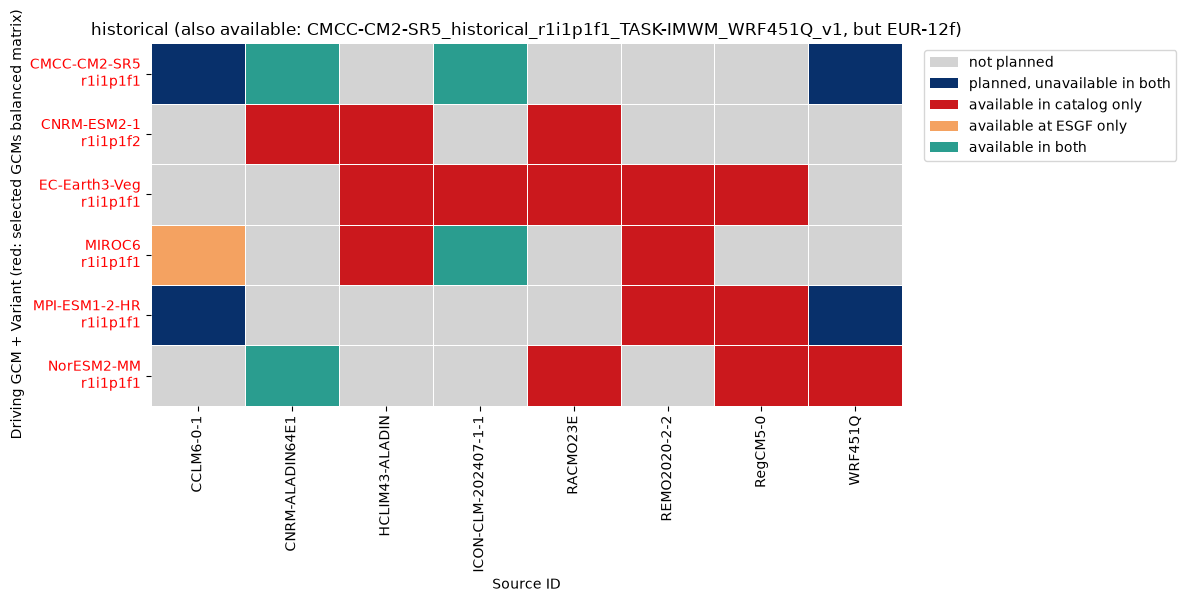

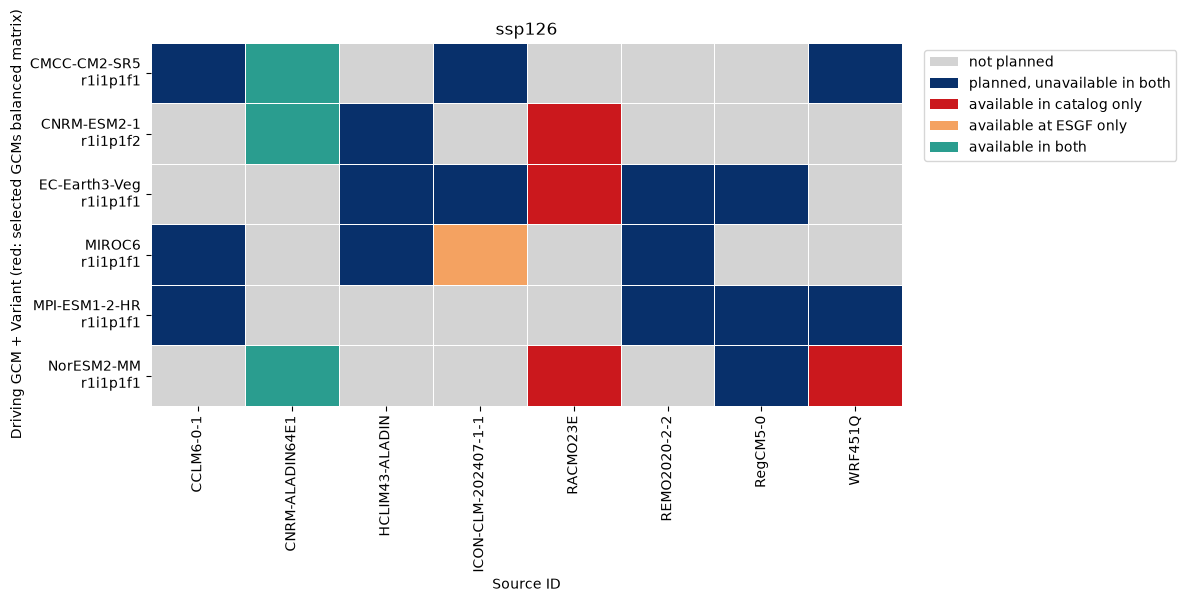

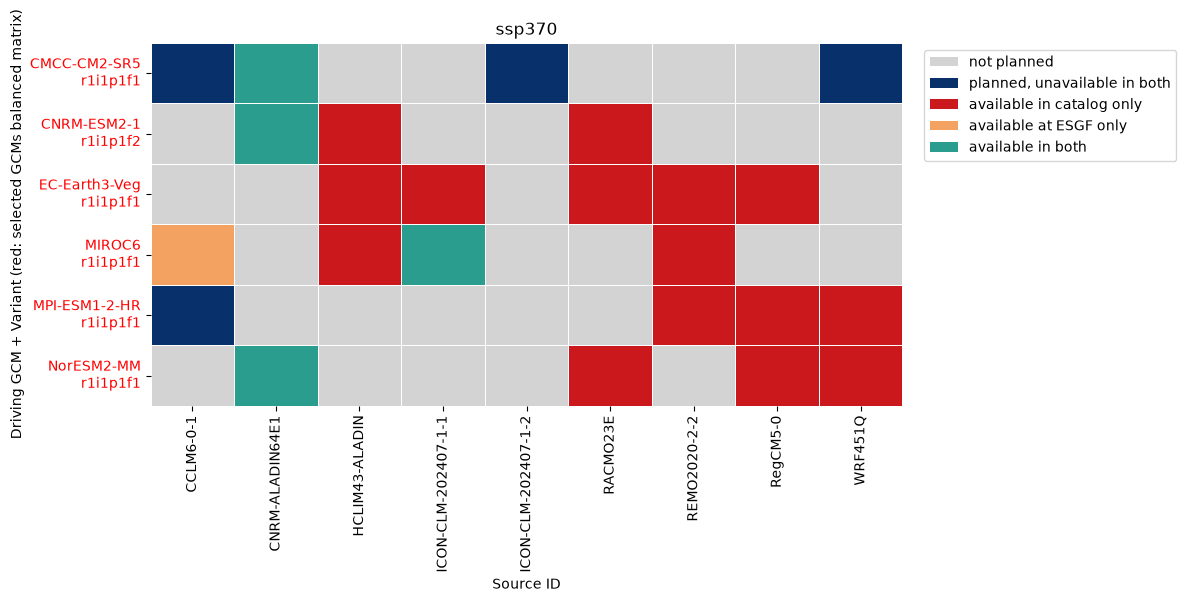

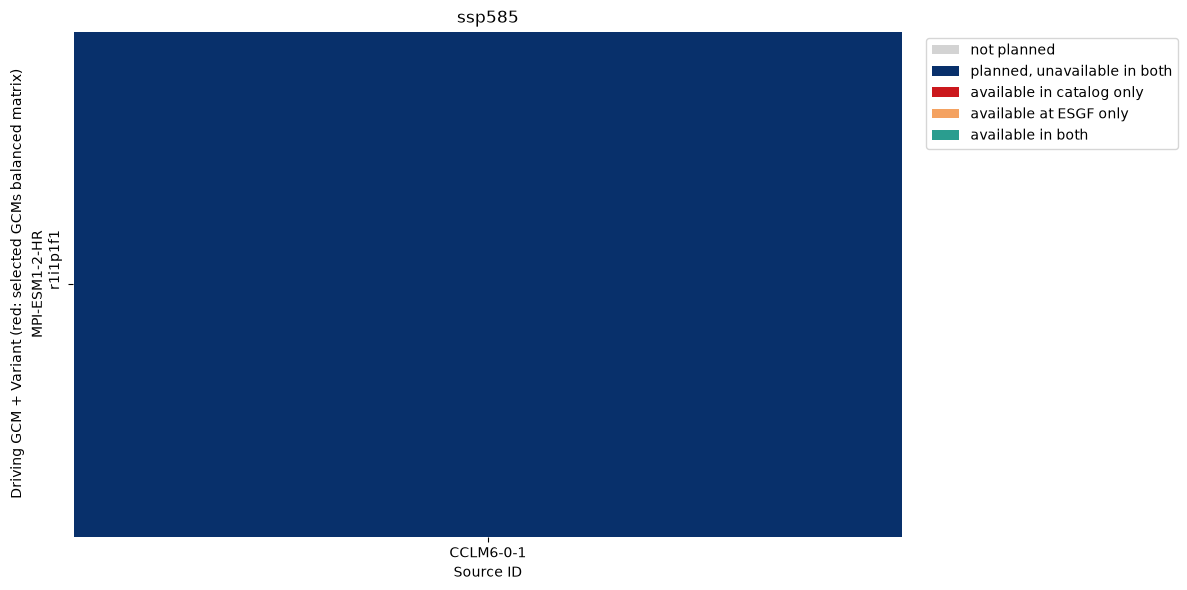

In [129]:
#--------------------------
# Select what you like to plot
#---------------------------------
# (1) just planed vs Jülich
#df = pd.read_csv("CMIP6_downscaling_plans_checked.csv")
#plot_cmip6_heatmaps(df, plot_dir, selected_variants, "plans_checked")

# (2)just planed vs Jülich BALANCED MATRIX
#plot_cmip6_heatmaps(df_eurbalanced, plot_dir, selected_variants, "plans_checked_balanced")

# (3)planed, Jülich esgf
df = pd.read_csv("CMIP6_downscaling_plans_checked_esgf.csv")
#
#plot_cmip6_heatmaps(df, plot_dir, selected_variants, "plans_checked_esgf")
#
# (4)or balance matrix
#
df_eurbalanced = create_balanced_matrix(df)
plot_cmip6_heatmaps(df_eurbalanced, plot_dir, selected_variants, "plans_checked_esgf_balanced")